# Notebook 3 of 3 - Demo

Runs the trained U-Net on a small sample of test tiles and shows the results. This notebook **is meant to be run** by the supervisor.

**Notes on this notebook**

- It uses a **random 200-tile subsample** of the test set (`demo_sample.hdf5`), not the full 10 GB test set, so it is quick to run and easy to share.
- The trained model (`crater_unet_best.pt`) is loaded and applied to these tiles.
- It is organised in two parts: **Part I** defines everything (model, extraction, helpers like in Notebook 2) and just needs to be run through. **Part II** is the actual demo: apply the model and look at the results.
- Most of the code here is reused from Notebooks 1 and 2, where it is explained in detail; it is kept uncommented here to stay compact.

**Contents of this notebook**

Part I: Setup
1. Imports and model definition
2. Extraction and helper functions
3. Load the sample and the trained model

Part II: Demo
1. Apply the U-Net to the sample
2. Example tiles: DEM, masks, and detected craters


# Part I: Setup

## 1. Imports and model definition

In [1]:
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

import torch
import torch.nn as nn

from skimage.feature import match_template, peak_local_max
from skimage.measure import label, regionprops
from scipy.optimize import least_squares
from scipy import ndimage
from sklearn.cluster import DBSCAN

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


In [2]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch,  out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_ch=1, base=32):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.e1 = ConvBlock(in_ch,   base)
        self.e2 = ConvBlock(base,    base*2)
        self.e3 = ConvBlock(base*2,  base*4)
        self.e4 = ConvBlock(base*4,  base*8)
        self.b  = ConvBlock(base*8,  base*16)
        self.u4 = nn.ConvTranspose2d(base*16, base*8, 2, stride=2); self.d4 = ConvBlock(base*16, base*8)
        self.u3 = nn.ConvTranspose2d(base*8,  base*4, 2, stride=2); self.d3 = ConvBlock(base*8,  base*4)
        self.u2 = nn.ConvTranspose2d(base*4,  base*2, 2, stride=2); self.d2 = ConvBlock(base*4,  base*2)
        self.u1 = nn.ConvTranspose2d(base*2,  base,   2, stride=2); self.d1 = ConvBlock(base*2,  base)
        self.out = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        c1 = self.e1(x)
        c2 = self.e2(self.pool(c1))
        c3 = self.e3(self.pool(c2))
        c4 = self.e4(self.pool(c3))
        b  = self.b(self.pool(c4))
        x = self.d4(torch.cat([self.u4(b), c4], dim=1))
        x = self.d3(torch.cat([self.u3(x), c3], dim=1))
        x = self.d2(torch.cat([self.u2(x), c2], dim=1))
        x = self.d1(torch.cat([self.u1(x), c1], dim=1))
        return torch.sigmoid(self.out(x))

## 2. Extraction and helper functions

The same crater-extraction pipeline used in Notebook 2: template matching plus the circle-and-arc fitting, combined into the U-Net method.

In [3]:
def make_ring(r, thickness=2):
    size = 2*r + 1
    yy, xx = np.ogrid[:size, :size]
    dist = np.sqrt((xx - r)**2 + (yy - r)**2)
    return (np.abs(dist - r) <= thickness).astype(np.float32)

In [4]:
def detect_craters_deepmoon(mask, radii, Pm=0.38, B=0.3, D_xy=1.8, D_r=1.0):
    binary = (mask > B).astype(np.float32)
    raw = []
    for r in radii:
        if 2*r + 1 >= min(binary.shape):
            continue
        corr = match_template(binary, make_ring(r), pad_input=True)
        for y, x in peak_local_max(corr, threshold_abs=Pm, min_distance=4):
            raw.append((x, y, r, corr[y, x]))
    kept = []
    for x, y, r, s in sorted(raw, key=lambda d: -d[3]):
        dup = False
        for kx, ky, kr, _ in kept:
            same_place = ((x-kx)**2 + (y-ky)**2) / min(r, kr)**2 < D_xy
            same_size  = abs(r - kr) / min(r, kr) < D_r
            if same_place and same_size:
                dup = True
                break
        if not dup:
            kept.append((x, y, r, s))
    return kept

In [5]:
R_MIN_PX = 1
R_MAX_PX = 100

def get_radius_range(tile_idx):
    return R_MIN_PX, R_MAX_PX

def circle_iou(d1, d2):
    x1, y1, r1 = d1[0], d1[1], d1[2]
    x2, y2, r2 = d2[0], d2[1], d2[2]
    dist = np.sqrt((x1-x2)**2 + (y1-y2)**2)
    if dist >= r1 + r2: return 0.0
    if dist <= abs(r1 - r2):
        smaller = min(r1, r2)**2
        larger  = max(r1, r2)**2
        return (np.pi * smaller) / (np.pi * larger + 1e-8)
    r1_sq  = r1**2
    r2_sq  = r2**2
    d_sq   = dist**2
    cos_a1 = np.clip((d_sq+r1_sq-r2_sq)/(2*dist*r1+1e-8), -1, 1)
    cos_a2 = np.clip((d_sq+r2_sq-r1_sq)/(2*dist*r2+1e-8), -1, 1)
    a1     = np.arccos(cos_a1)
    a2     = np.arccos(cos_a2)
    intersection = (r1_sq*(a1-np.sin(2*a1)/2) + r2_sq*(a2-np.sin(2*a2)/2))
    union = np.pi*(r1_sq+r2_sq) - intersection
    return intersection / (union + 1e-8)

def fit_circle_to_points(x_points, y_points):
    if len(x_points) < 5: return None

    cx0 = np.mean(x_points)
    cy0 = np.mean(y_points)
    r0  = np.mean(np.sqrt((x_points-cx0)**2 +
                           (y_points-cy0)**2))
    if r0 < 1: return None

    def residuals(params):
        cx, cy, r = params
        dist = np.sqrt((x_points-cx)**2 + (y_points-cy)**2)
        return dist - r
    try:

        result    = least_squares(residuals, x0=[cx0, cy0, r0],method='lm', max_nfev=500)
        cx, cy, r = result.x
        residual  = np.mean(np.abs(result.fun))
        return cx, cy, abs(r), residual
    except Exception: return None

def fit_circle_from_arc(x_points, y_points):
    if len(x_points) < 5: return None
    if max(x_points.max()-x_points.min(),y_points.max()-y_points.min()) < 5: return None
    return fit_circle_to_points(x_points, y_points)

def fit_circle_to_points_weighted(x_points, y_points,weights=None):
    if len(x_points) < 5:return None
    if weights is None:weights = np.ones(len(x_points))
    weights = weights / (weights.sum() + 1e-8)
    cx0 = np.sum(weights * x_points)
    cy0 = np.sum(weights * y_points)
    r0  = np.mean(np.sqrt((x_points-cx0)**2 +(y_points-cy0)**2))
    if r0 < 1:return None
    def residuals(params):
        cx, cy, r = params
        dist = np.sqrt((x_points-cx)**2 + (y_points-cy)**2)
        return (dist - r) * weights * len(weights)
    try:
        result    = least_squares(residuals, x0=[cx0, cy0, r0],method='lm', max_nfev=500)
        cx, cy, r = result.x
        residual  = np.mean(np.abs(result.fun / (weights*len(weights)+1e-8)))
        return cx, cy, abs(r), residual
    except Exception:
        return None

def split_component(x_points, y_points, min_cluster_size=5):
    if len(x_points) < min_cluster_size * 2: return [(x_points, y_points)]
    coords = np.column_stack([x_points, y_points])

    db     = DBSCAN(eps=8, min_samples=min_cluster_size).fit(coords)
    labels = db.labels_
    groups = []
    for lab in set(labels):
        if lab == -1:continue
        mask = labels == lab
        if mask.sum() >= min_cluster_size:groups.append((x_points[mask], y_points[mask]))
    return groups if groups else [(x_points, y_points)]

def fit_two_circles(x_points, y_points):
    if len(x_points) < 15:return None
    x_mid  = np.median(x_points)
    y_mid  = np.median(y_points)
    left   = x_points <= x_mid
    right  = x_points > x_mid
    top    = y_points <= y_mid
    bot    = y_points > y_mid
    splits = []
    if left.sum() >= 5 and right.sum() >= 5: splits.append((left, right))
    if top.sum() >= 5 and bot.sum() >= 5: splits.append((top, bot))
    if not splits: return None
    best_result         = None
    best_total_residual = float('inf')
    for m1, m2 in splits:
        r1 = fit_circle_from_arc(x_points[m1], y_points[m1])
        r2 = fit_circle_from_arc(x_points[m2], y_points[m2])
        if r1 is None or r2 is None: continue
        total = (r1[3] + r2[3]) / 2
        if total < best_total_residual:
            best_total_residual = total
            best_result         = (r1, r2)
    return best_result

def detect_craters_from_mask(prob_mask, tile_idx, prob_threshold = 0.3, min_pixels = 10,max_residual = 2.5, min_coverage = 0.25, max_radius_fraction = 0.35, split_large = True, split_threshold = 200, try_two_circles = True):
    r_min, r_max = get_radius_range(tile_idx)
    r_abs_max       = int(256 * max_radius_fraction)
    binary  = (prob_mask > prob_threshold).astype(np.uint8)
    labeled = label(binary, connectivity=2)
    regions = regionprops(labeled)

    detections = []

    for region in regions:
        if region.area < min_pixels: continue
        coords   = region.coords
        y_pts    = coords[:, 0].astype(float)
        x_pts    = coords[:, 1].astype(float)
        if split_large and region.area > split_threshold:
            groups  = split_component(x_pts, y_pts)
        else:
            groups = [(x_pts, y_pts)]

        for x_grp, y_grp in groups:
            if len(x_grp) < min_pixels: continue
            result        = fit_circle_to_points(x_grp, y_grp)
            single_worked = False

            if result is not None:
                cx, cy, r, res = result
                margin   = r * 0.3
                expected = 2 * np.pi * r
                coverage = min(1.0, len(x_grp) / expected)

                if (r_min <= r <= min(r_max, r_abs_max) and
                        res <= max_residual and
                        margin <= cx < 256-margin and
                        margin <= cy < 256-margin and
                        coverage >= min_coverage):

                    detections.append({
                        'x': float(cx), 'y': float(cy),
                        'r': float(r),  'residual': float(res),
                        'coverage': float(coverage),
                        'n_pixels': int(len(x_grp)),
                        'source':   'circle'})
                    single_worked  = True

            if (not single_worked and try_two_circles and len(x_grp) >= r_min * 4):
                two = fit_two_circles(x_grp, y_grp)
                if two is not None:
                    for cx, cy, r, res in two:
                        if not (r_min <= r <= min(r_max, r_abs_max)): continue
                        if res > max_residual * 1.5: continue
                        if not (0 <= cx < 256 and 0 <= cy < 256): continue
                        expected = 2 * np.pi * r
                        coverage = min(1.0, len(x_grp)/2 / expected)
                        if coverage < min_coverage * 0.5: continue
                        detections.append({
                            'x': float(cx), 'y': float(cy),
                            'r': float(r),  'residual': float(res),
                            'coverage': float(coverage),
                            'n_pixels': int(len(x_grp)//2),
                            'source':   'circle_pair'})
    return detections

def subtract_detected_rims(prob_mask, detections,tile_idx, rim_thickness=4):
    residual       = prob_mask.copy()
    H, W           = prob_mask.shape
    y_grid, x_grid = np.ogrid[:H, :W]
    for d in detections:
        cx, cy, r    = d['x'], d['y'], d['r']
        dist_centre  = np.sqrt((x_grid-cx)**2 + (y_grid-cy)**2)
        dist_rim     = np.abs(dist_centre - r)
        residual[dist_rim <= rim_thickness] = 0.0
    return residual

def detect_arcs_improved(residual_mask, tile_idx,prob_threshold = 0.2, min_pixels = 8,max_residual = 6.0, min_span = 6, min_coverage = 0.10, max_radius_fraction = 0.45, split_large = True, split_threshold = 150):
    r_min, r_max = get_radius_range(tile_idx)
    r_abs_max       = int(256 * max_radius_fraction)

    binary  = (residual_mask > prob_threshold).astype(np.uint8)
    labeled = label(binary, connectivity=2)
    regions = regionprops(labeled)

    detections = []
    for region in regions:
        if region.area < min_pixels: continue
        coords  = region.coords
        y_pts   = coords[:, 0].astype(float)
        x_pts   = coords[:, 1].astype(float)

        if max(x_pts.max()-x_pts.min(), y_pts.max()-y_pts.min()) < min_span: continue

        if split_large and region.area > split_threshold: groups = split_component(x_pts, y_pts)
        else: groups = [(x_pts, y_pts)]

        for x_grp, y_grp in groups:
            if len(x_grp) < min_pixels: continue
            w_grp = np.array([residual_mask[int(y), int(x)] for x, y in zip(x_grp, y_grp)])
            result = fit_circle_to_points_weighted(x_grp, y_grp, w_grp)
            if result is None: result = fit_circle_from_arc(x_grp, y_grp)
            if result is None: continue

            cx, cy, r, res = result

            if r < r_min or r > r_abs_max: continue
            if res > max_residual: continue
            if not (0 <= cx < 256 and 0 <= cy < 256):continue

            expected = 2 * np.pi * r
            coverage = min(1.0, len(x_grp) / expected)

            if coverage < min_coverage: continue

            detections.append({
                'x': float(cx), 'y': float(cy),
                'r': float(r),  'residual': float(res),
                'coverage': float(coverage),
                'n_pixels': int(len(x_grp)),
                'source':   'arc'})
    return detections

def detect_all_craters(prob_mask, tile_idx):

    det_circles = detect_craters_from_mask(prob_mask, tile_idx = tile_idx, prob_threshold = 0.5, min_pixels = 10, max_residual = 2.5, min_coverage = 0.25, max_radius_fraction = 0.35, split_large = True, split_threshold = 200, try_two_circles = True)

    residual_mask = subtract_detected_rims(
        prob_mask, det_circles, tile_idx, rim_thickness=4)

    det_arcs = detect_arcs_improved(residual_mask, tile_idx = tile_idx, prob_threshold = 0.4, min_pixels = 5, max_residual = 6.0, min_span = 6, min_coverage = 0.10, max_radius_fraction = 0.45, split_large = True,split_threshold = 150)

    all_raw = det_circles + det_arcs
    unified = [(d['x'], d['y'], d['r'], max(0.0, 1.0 - d['residual']*0.1),  d['source'], d['coverage'],                        d['residual'])  for d in all_raw]
    unified = sorted(unified, key=lambda d: d[3], reverse=True)

    kept = []
    while unified:
        best = unified.pop(0)
        kept.append(best)
        unified = [d for d in unified if circle_iou(best, d) < 0.3]

    final = [{'x': x, 'y': y, 'r': r, 'nms_score': s, 'source': src, 'coverage': true_cov, 'residual': true_res} for x, y, r, s, src, true_cov, true_res in kept]

    return final, residual_mask


In [6]:
def extract_circlearc_on(image, tile_idx):
    dets, _ = detect_all_craters(image, tile_idx=tile_idx)
    return [(d['x'], d['y'], d['r'], d.get('coverage', 1.0)) for d in dets]

def extract_unet(j, D_xy=1.8, D_r=1.0):
    r_min, r_max = get_radius_range(j)
    tm = detect_craters_deepmoon(preds[j], radii=range(r_min, r_max + 1), Pm=0.38)
    ca = extract_circlearc_on(preds[j], j)
    kept = []
    for x, y, r, s in tm + ca:
        if not any(((x-kx)**2+(y-ky)**2)/min(r,kr)**2 < D_xy and abs(r-kr)/min(r,kr) < D_r
                   for kx,ky,kr,_ in kept):
            kept.append((x, y, r, s))
    return kept

## 3. Load the sample and the trained model
Eventually adapt the paths.

In [7]:
# load the 200-tile demo sample (DEMs, true masks, per-tile metadata)
with h5py.File('demo_sample.hdf5', 'r') as fh:
    X = fh['input_images'][:].astype('float32') / 255.0
    Y = fh['target_masks'][:].astype('float32')
X = X[..., np.newaxis]
SRC_CRATERS = 'demo_craters.hdf5'
print('loaded', X.shape[0], 'demo tiles')

# load the trained model
model = UNet().to(device)
model.load_state_dict(torch.load('crater_unet_best.pt', map_location=device))
model.eval()
print('model loaded')

loaded 200 demo tiles
model loaded


# Part II: Demo

## 4. Apply the U-Net to the sample

Runs every demo tile through the network to produce the predicted rim masks.

In [8]:
def to_tensor(X):
    return torch.from_numpy(X).permute(0, 3, 1, 2).contiguous()

@torch.no_grad()
def predict(X, batch=16):
    model.eval()
    out = []
    for i in range(0, len(X), batch):
        xb = to_tensor(X[i:i+batch]).to(device)
        out.append(model(xb).cpu().numpy()[:, 0])
    return np.concatenate(out)

preds = predict(X)
print('predicted masks:', preds.shape)

predicted masks: (200, 256, 256)


## 5. Example tiles: DEM, masks, and detected craters

For each tile, four panels: the raw DEM, the U-Net mask next to the true mask, the detected craters (cyan) next to the catalogue craters (red), and a breakdown of correctly found (green) vs. missed (magenta) craters plus false positives (yellow).

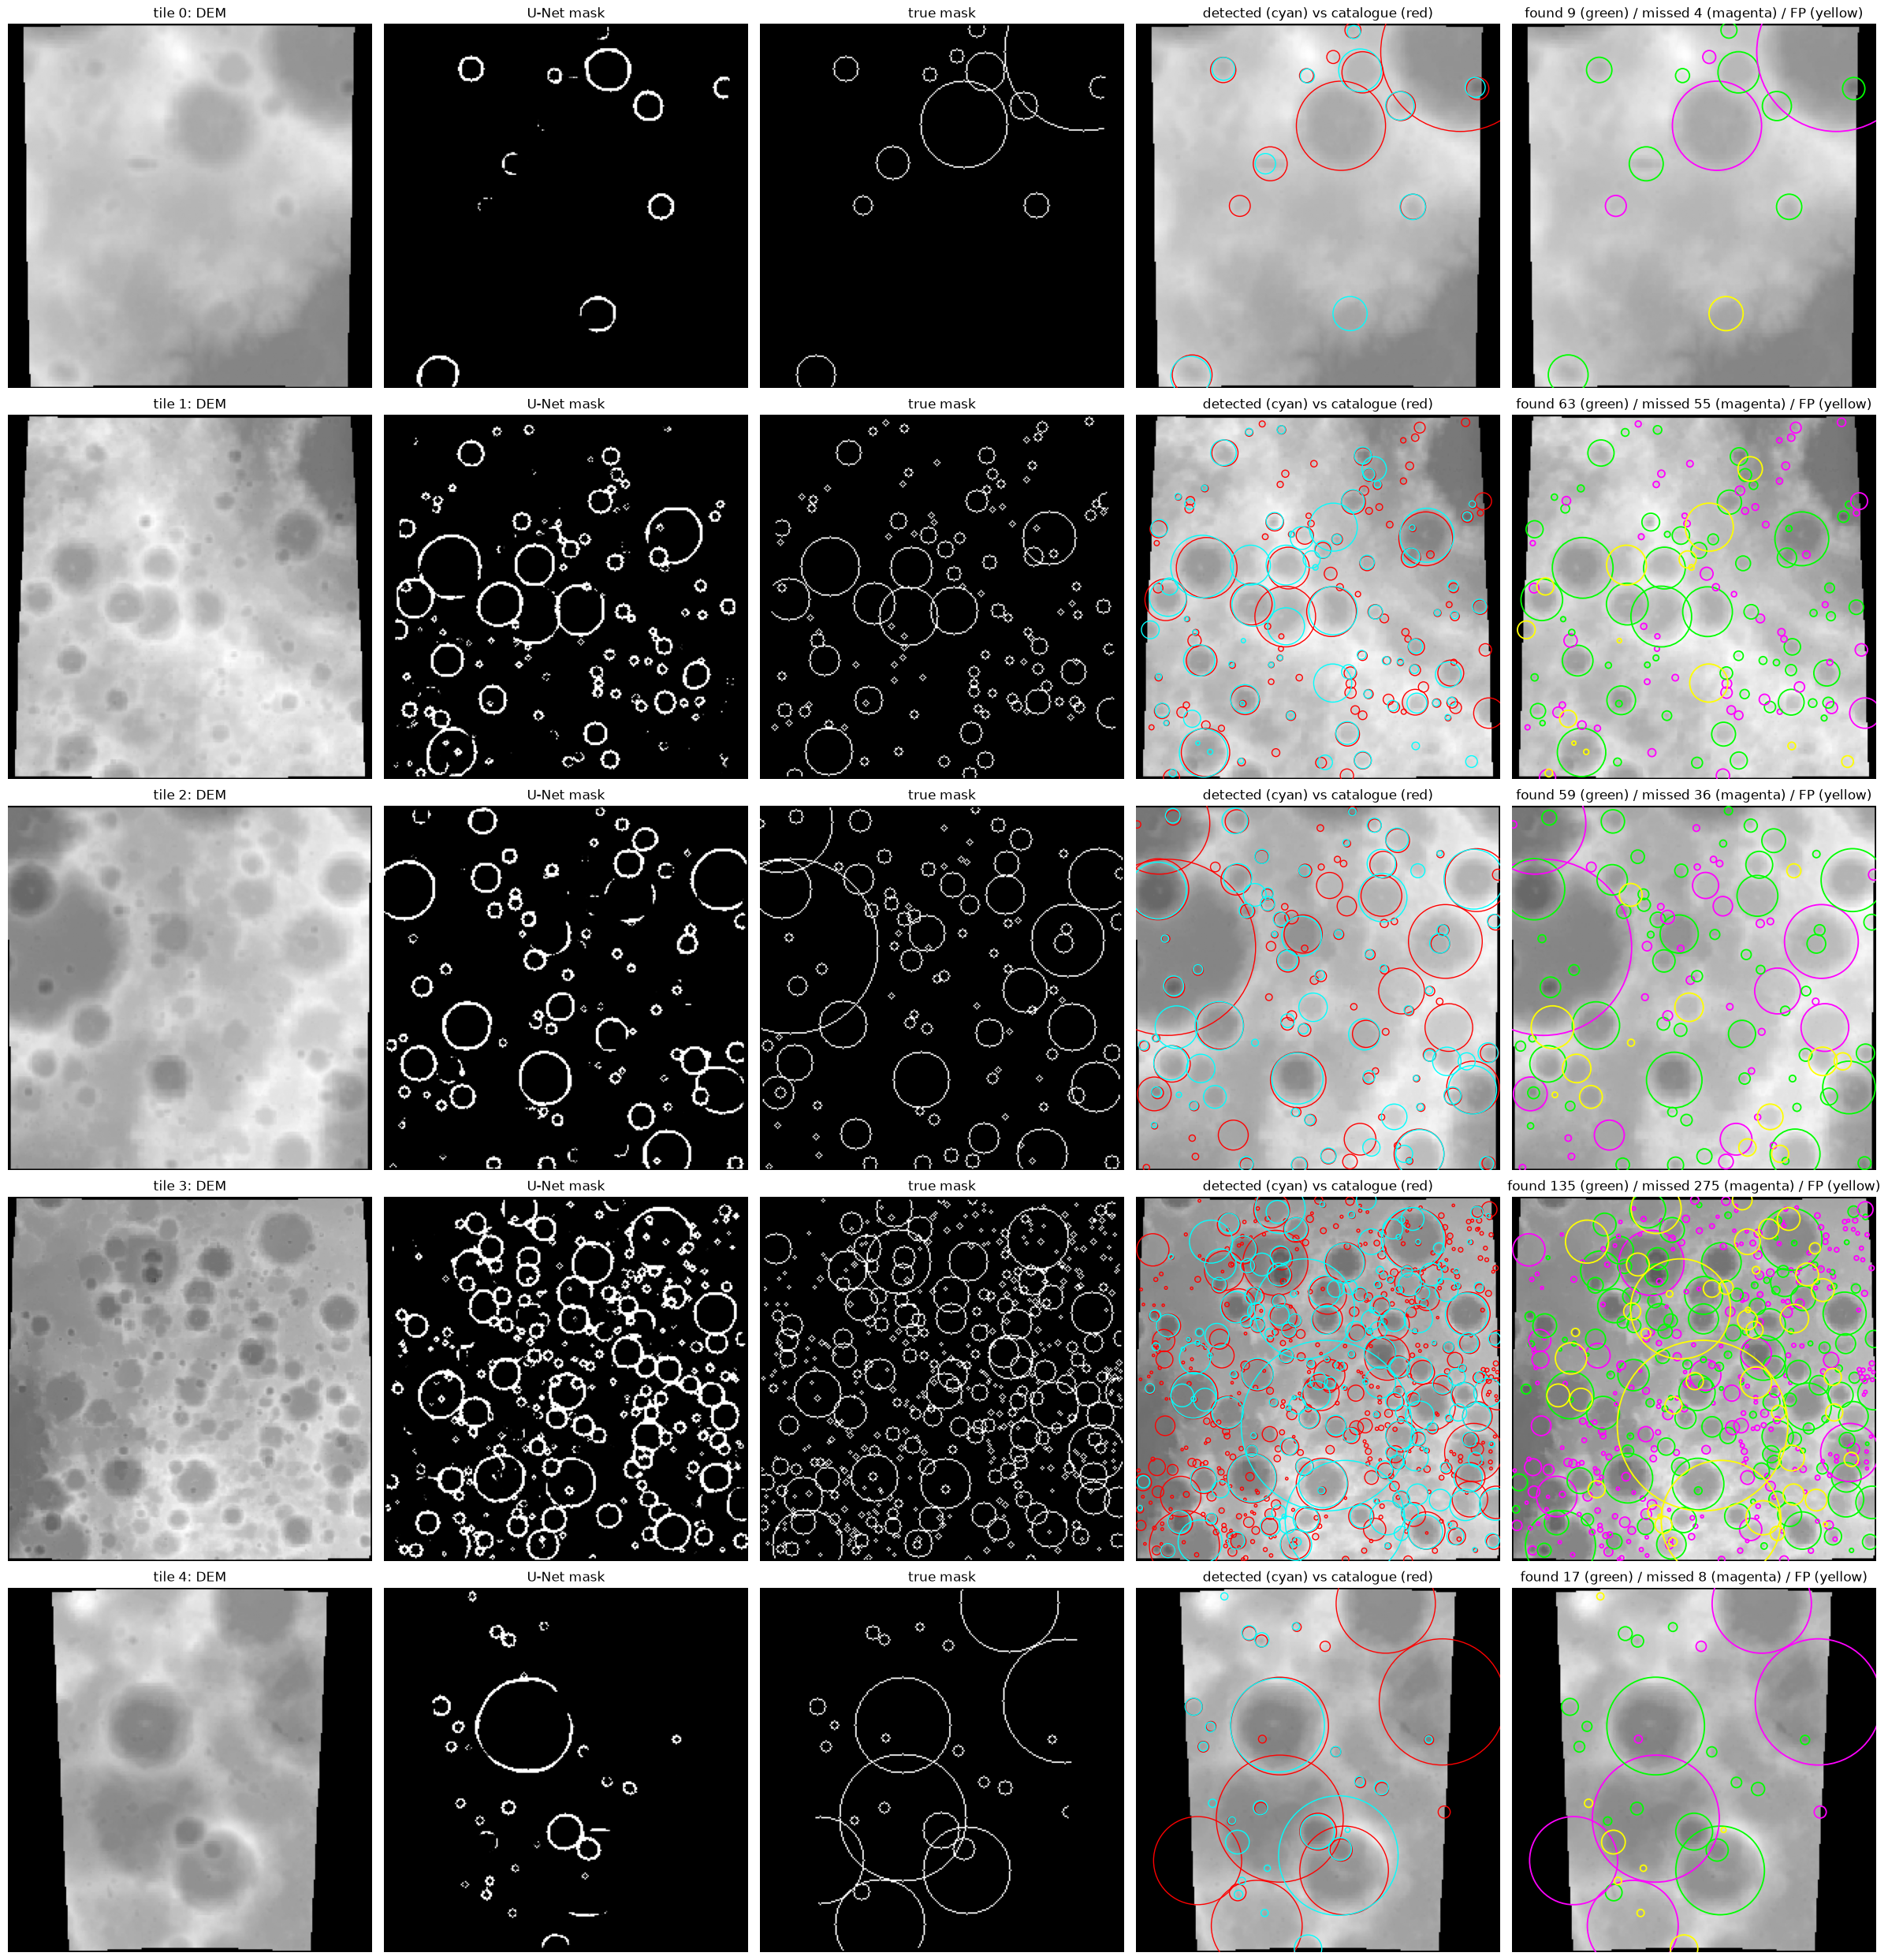

In [9]:
def demo_tiles(tiles, r_min=1, r_max=100, D_xy=1.8, D_r=1.0):
    fig, ax = plt.subplots(len(tiles), 5, figsize=(24, 5*len(tiles)))
    stored = pd.HDFStore(SRC_CRATERS, 'r')
    for row, j in enumerate(tiles):
        dem = X[j, ..., 0]; mask = preds[j]; true_mask = Y[j]
        cat = stored[f"/img_{j:05d}"]
        truth = [(c['x'], c['y'], c['Diameter (pix)']/2)
                 for _, c in cat.iterrows() if r_min <= c['Diameter (pix)']/2 <= r_max]
        dets = [d for d in extract_unet(j) if r_min <= d[2] <= r_max]

        matched_t, matched_d = set(), set()
        for di, (x, y, r, *_ ) in enumerate(sorted(dets, key=lambda d: -d[3])):
            for k, (tx, ty, tr) in enumerate(truth):
                if k in matched_t: continue
                if ((x-tx)**2+(y-ty)**2)/min(r,tr)**2 < D_xy and abs(r-tr)/min(r,tr) < D_r:
                    matched_t.add(k); matched_d.add(di); break
        sd = sorted(dets, key=lambda d: -d[3])
        false_pos = [sd[di] for di in range(len(sd)) if di not in matched_d]

        # panel 0: raw DEM
        ax[row,0].imshow(dem, cmap='gray'); ax[row,0].set_title(f'tile {j}: DEM')
        # panel 1: predicted mask
        ax[row,1].imshow(mask, cmap='gray'); ax[row,1].set_title('U-Net mask')
        # panel 2: true mask
        ax[row,2].imshow(true_mask, cmap='gray'); ax[row,2].set_title('true mask')
        # panel 3: detected (cyan) vs catalogue (red)
        ax[row,3].imshow(dem, cmap='gray'); ax[row,3].set_title('detected (cyan) vs catalogue (red)')
        for _, c in cat.iterrows():
            ax[row,3].add_patch(Circle((c['x'], c['y']), c['Diameter (pix)']/2, fill=False, color='red', lw=1.0))
        for x, y, r, s in dets:
            ax[row,3].add_patch(Circle((x, y), r, fill=False, color='cyan', lw=1.0))
        # panel 4: found (green) / missed (magenta) / false positive (yellow)
        ax[row,4].imshow(dem, cmap='gray')
        n_found = len(matched_t); n_missed = len(truth)-n_found
        ax[row,4].set_title(f'found {n_found} (green) / missed {n_missed} (magenta) / FP (yellow)')
        for k, (tx, ty, tr) in enumerate(truth):
            cc = 'lime' if k in matched_t else 'magenta'
            ax[row,4].add_patch(Circle((tx, ty), tr, fill=False, color=cc, lw=1.3))
        for x, y, r, s in false_pos:
            ax[row,4].add_patch(Circle((x, y), r, fill=False, color='yellow', lw=1.3))
        for a in ax[row]: a.axis('off')
    stored.close()
    plt.tight_layout(); plt.show()

demo_tiles([0, 1, 2, 3, 4]) # pick any tiles from 0-199